# 11 图像描述：CNN 编码图片，GRU 逐词生成句子

用受控的“颜色 × 形状”图片学习真正的编码器—解码器训练：RGB 输入 → 视觉向量 → 词元矩阵 → 句子。
默认不下载大模型。这是小词表、短句子的教学任务；不是能理解任意自然照片的通用视觉语言模型。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("请从完整项目的根目录或 notebooks 目录运行。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import torch
from torch import nn
import torch.nn.functional as F
dev = device()
torch.set_num_threads(2)
print("计算设备:", dev)


计算设备: cpu


## 1. 数据：图像与完整句子成对

标签句子由数据生成器定义为 “a red circle”等。训练时只输入图像与前缀词，预测下一个词；测试生成时不提供答案。位置与大小随机，训练/测试种子分离。


图像 NCHW: (360, 3, 32, 32) 句子 token 矩阵:
 tensor([[1, 3, 6, 9, 2],
        [1, 3, 6, 8, 2],
        [1, 3, 4, 7, 2],
        [1, 3, 6, 7, 2],
        [1, 3, 4, 9, 2]])
RGB 局部矩阵:
 [[[0.13725491 0.27450982 0.9019608 ]
  [0.13725491 0.27450982 0.9019608 ]
  [0.13725491 0.27450982 0.9019608 ]]

 [[0.13725491 0.27450982 0.9019608 ]
  [0.13725491 0.27450982 0.9019608 ]
  [0.13725491 0.27450982 0.9019608 ]]

 [[0.13725491 0.27450982 0.9019608 ]
  [0.13725491 0.27450982 0.9019608 ]
  [0.13725491 0.27450982 0.9019608 ]]]


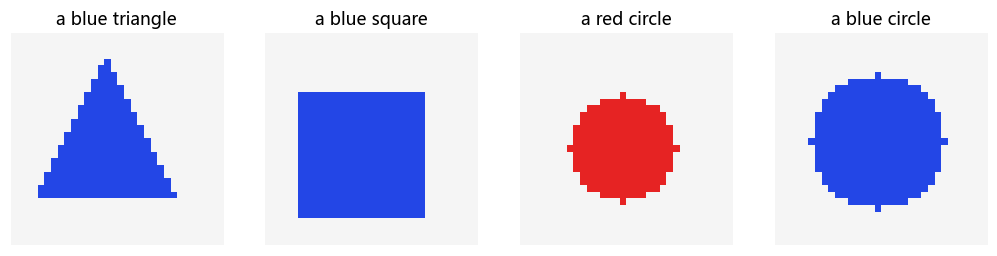

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/11_caption_inputs.png')

In [2]:
words = ["<pad>", "<bos>", "<eos>", "a", "red", "green", "blue", "circle", "square", "triangle"]
stoi = {word: i for i, word in enumerate(words)}
palette = [(230, 35, 35), (35, 200, 35), (35, 70, 230)]
color_names = ["red", "green", "blue"]
shape_names = ["circle", "square", "triangle"]
def caption_data(n, seed):
    rng = np.random.default_rng(seed)
    xs, ys = [], []
    for _ in range(n):
        c, s = int(rng.integers(3)), int(rng.integers(3))
        im = np.full((32, 32, 3), 245, np.uint8)
        x, y = rng.integers(13, 20, size=2); r = int(rng.integers(7, 11))
        if s == 0: cv2.circle(im, (x, y), r, palette[c], -1)
        elif s == 1: cv2.rectangle(im, (x-r, y-r), (x+r, y+r), palette[c], -1)
        else: cv2.fillPoly(im, [np.array([[x, y-r], [x-r, y+r], [x+r, y+r]])], palette[c])
        xs.append(im.transpose(2, 0, 1)/255.)
        ys.append([stoi["<bos>"], stoi["a"], stoi[color_names[c]], stoi[shape_names[s]], stoi["<eos>"]])
    return torch.tensor(np.array(xs), dtype=torch.float32), torch.tensor(ys, dtype=torch.long)

train_x, train_y = caption_data(360, 10)
test_x, test_y = caption_data(90, 999)
print("图像 NCHW:", tuple(train_x.shape), "句子 token 矩阵:\n", train_y[:5])
print("RGB 局部矩阵:\n", train_x[0, :, 14:17, 14:17].permute(1, 2, 0).numpy())
fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axs):
    ax.imshow(train_x[i].permute(1, 2, 0)); ax.set_title(" ".join(words[t] for t in train_y[i, 1:-1])); ax.axis("off")
save_figure("11_caption_inputs")


## 2. 网络结构

CNN 把图片编码为 64 维向量，用它初始化 GRU 的隐藏状态，并在每个时间步与词向量拼接。
Embedding 把词编号变成向量；GRU 输出每个位置的词表 logits。训练采用 teacher forcing，推理则使用自己上一步预测的词。

维度怎么读：图像是 `[N,3,32,32]`，句子是 `[N,5]` 个整数词编号；例如 `[1,3,6,9,2]` 对应 `<bos> a blue triangle <eos>`。编号只是查词表的索引，数值大小不表示语义相似。输入前 4 个词预测后 4 个词，故 logits 为 `[N,4,10]`；对最后一维取 argmax 后得到 `[N,4]` 预测词编号。


In [3]:
class TinyCaptioner(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Conv2d(3, 12, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                     nn.Conv2d(12, 20, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                     nn.Flatten(), nn.Linear(20*8*8, 64), nn.LayerNorm(64))
        self.embedding = nn.Embedding(len(words), 24)
        self.decoder = nn.GRU(24+64, 64, batch_first=True)
        self.head = nn.Linear(64, len(words))
    def forward(self, image, prefix):
        features = self.encoder(image)
        hidden = features[None]
        inputs = torch.cat([self.embedding(prefix), features[:, None].expand(-1, prefix.shape[1], -1)], dim=-1)
        output, _ = self.decoder(inputs, hidden)
        return self.head(output)
    def generate(self, image):
        features = self.encoder(image)
        hidden = features[None]
        token = torch.full((len(image), 1), stoi["<bos>"], dtype=torch.long, device=image.device)
        result = []
        for _ in range(4):
            inputs = torch.cat([self.embedding(token), features[:, None]], dim=-1)
            out, hidden = self.decoder(inputs, hidden)
            token = self.head(out).argmax(-1)
            result.append(token[:, 0])
        return torch.stack(result, dim=1)

model = TinyCaptioner().to(dev)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_x, train_y = train_x.to(dev), train_y.to(dev)
print("编码向量形状:", tuple(model.encoder(train_x[:2]).shape))
print("输出 logits [batch,时间,词表]:", tuple(model(train_x[:2], train_y[:2, :-1]).shape))


编码向量形状: (2, 64)
输出 logits [batch,时间,词表]: (2, 4, 10)


## 3. 训练：预测每一个“下一个词”

交叉熵直接接收 logits，不先做 Softmax。批次随机抽样；固定种子方便比较。


初期/末期损失: 1.5583805680274962 0.003822975279763341


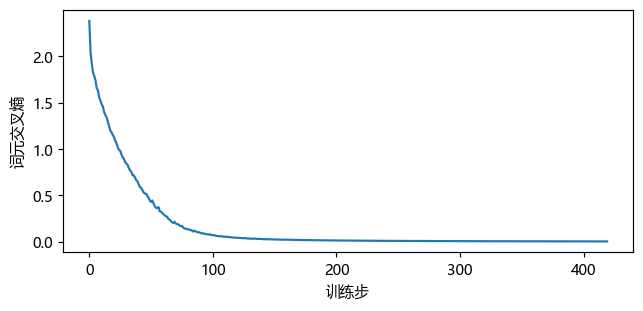

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/11_caption_loss.png')

In [4]:
losses = []
model.train()
for step in range(420):
    ids = torch.randint(len(train_x), (32,), device=dev)
    logits = model(train_x[ids], train_y[ids, :-1])
    loss = F.cross_entropy(logits.reshape(-1, len(words)), train_y[ids, 1:].reshape(-1))
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    losses.append(loss.item())
print("初期/末期损失:", np.mean(losses[:20]), np.mean(losses[-20:]))
plt.figure(figsize=(7, 3)); plt.plot(losses); plt.xlabel("训练步"); plt.ylabel("词元交叉熵")
save_figure("11_caption_loss")


## 4. 独立图片 → 逐词输出 → 完整句子

推理时只给 `<bos>`；颜色与形状必须来自图像编码，不能从标签或文件名读取。


保留集句子全对率=1.000, token准确率=1.000
图像编码向量前 8 维:
 [[-1.224e+00 -1.596e+00  2.083e+00  6.750e-01 -2.191e+00  2.930e-01
   4.720e-01 -1.142e+00]
 [-1.401e+00 -1.043e+00  1.946e+00  4.430e-01 -1.329e+00 -1.260e-01
   9.380e-01 -2.000e-03]]
预测 token 矩阵:
 [[3 6 9 2]
 [3 6 7 2]
 [3 4 9 2]
 [3 5 8 2]
 [3 4 8 2]]


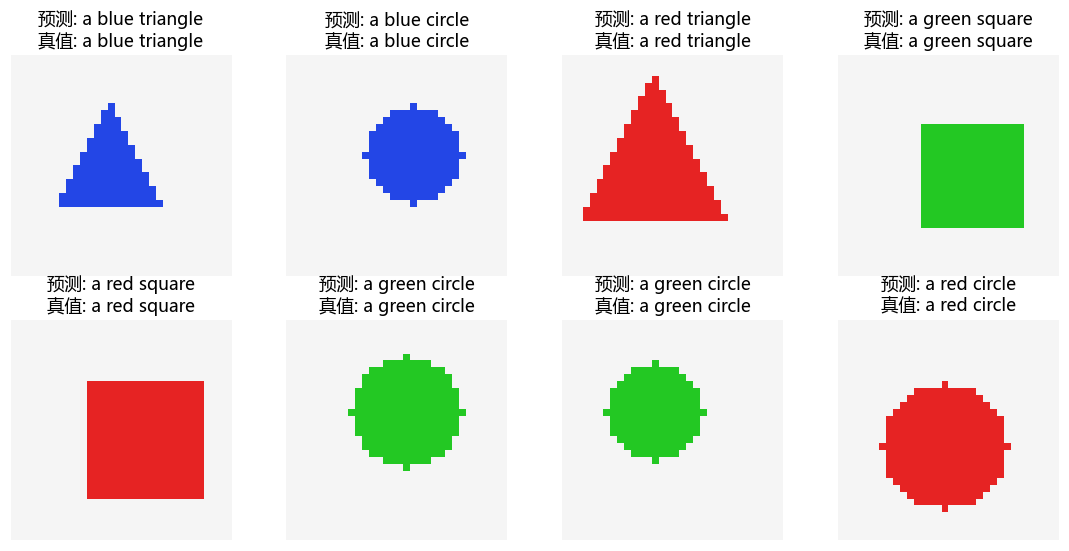

In [5]:
model.eval()
with torch.no_grad():
    predictions = model.generate(test_x.to(dev)).cpu()
    visual_vectors = model.encoder(test_x[:2].to(dev)).cpu().numpy()
def decode(tokens):
    return " ".join(words[int(i)] for i in tokens if words[int(i)] not in ["<bos>", "<eos>", "<pad>"])
exact = (predictions == test_y[:, 1:]).all(1).float().mean().item()
token_acc = (predictions == test_y[:, 1:]).float().mean().item()
print(f"保留集句子全对率={exact:.3f}, token准确率={token_acc:.3f}")
print("图像编码向量前 8 维:\n", np.round(visual_vectors[:, :8], 3))
print("预测 token 矩阵:\n", predictions[:5].numpy())
fig, axs = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axs.flat):
    ax.imshow(test_x[i].permute(1, 2, 0)); ax.set_title(f"预测: {decode(predictions[i])}\n真值: {decode(test_y[i])}"); ax.axis("off")
save_figure("11_caption_outputs")
assert predictions.shape == test_y[:, 1:].shape


## 5. 为什么不能直接描述真实照片

当前词表只有颜色、几何形状，没有“人、动物、动作”等词，训练图也没有这些场景。
即使对自然照片输出一句通顺的句子，也可能是错误外推。通用图像描述需要真实图文数据与更强的视觉/语言编码器。

练习：添加 yellow 和 rectangle，并同步修改数据生成器与词表；将老师强制输入的前缀换成自回归训练，观察差异。


## 6. 参考与扩展

- [Show and Tell 原论文](https://arxiv.org/abs/1411.4555)：图像编码器与语言解码器的经典思路。
- [PyTorch GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html)：接口与隐藏状态形状。
- 本课为独立的小型受控任务实现，没有复制论文训练结果。
